# <center> Проект Классификации

Основная задача заключается в том, чтобы создать, обучить и применить модели машинного обучения с целью выявления наличия огня на изображении.  
А также, понять какая модель справится эффективнее, предварительно выявив по каким параметрам модель обучится лучше всего.  
Данная задача выбрана мной для получения опыта работы с данными изображений, которая сможет послужить базой для работы с видеопотоком с целью детекции пожаров в реальном времени.

Основные этапы данного исследования:  
1. Этап чтения и первичной визуализации данных
2. Разведывательный анализ данных, экстракция признаков из изображения и их визуализация
3. Обучение бейслайна
4. Анализ бейслайна и признаков данных
5. Эксперименты с типами моделей и их комбинации
6. Обучение модели глубокого машинного обучения и сравнение метрик 
7. Подведение итогов 

In [1]:
# Импорт библиотек
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, recall_score, precision_recall_curve, auc
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from scipy.stats import entropy
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from scipy import stats
from sklearn.inspection import permutation_importance
import lightgbm as lgb
import tensorflow as tf
from tensorflow.keras import layers, Sequential
from sklearn.utils.class_weight import compute_class_weight
from lightgbm import LGBMClassifier
import json
from urllib.parse import urlparse


import warnings
warnings.filterwarnings('ignore')


## Чтение данных

In [2]:
dataset_path = 'C:/Users/user/Desktop/IDE/data'
data = []


for category in ['fire', 'nofire']:
    path = os.path.join(dataset_path, category)
    class_num = 1 if category == 'fire' else 0 
    for img in os.listdir(path):
        img_path = os.path.join(path, img)
        data.append([img_path, class_num])

df = pd.DataFrame(data, columns=['filepath', 'label'])
print(df.head())
print(f"Общее количество изображений: {len(df)}")

                                       filepath  label
0  C:/Users/user/Desktop/IDE/data\fire\0001.png      1
1  C:/Users/user/Desktop/IDE/data\fire\0002.png      1
2  C:/Users/user/Desktop/IDE/data\fire\0003.png      1
3  C:/Users/user/Desktop/IDE/data\fire\0004.png      1
4  C:/Users/user/Desktop/IDE/data\fire\0005.png      1
Общее количество изображений: 2947


Посмотрим на распределение данных по признаку наличия огня 

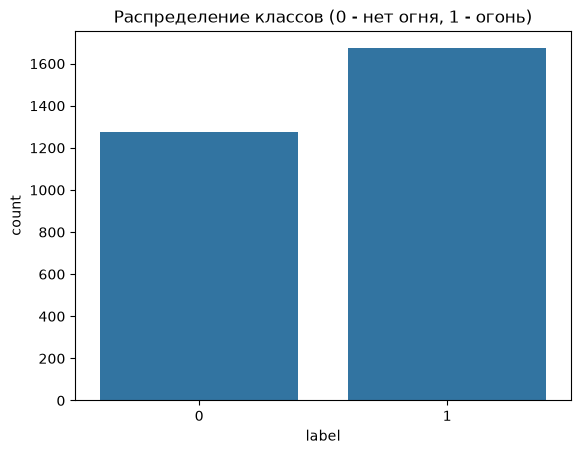

label
1    1672
0    1275
Name: count, dtype: int64


In [3]:
sns.countplot(x='label', data=df)
plt.title('Распределение классов (0 - нет огня, 1 - огонь)')
plt.show()
print(df['label'].value_counts())

Выведем изображения с целью убедиться что чтение файла файлов прошло успешно и лейблы соотвествуют факту

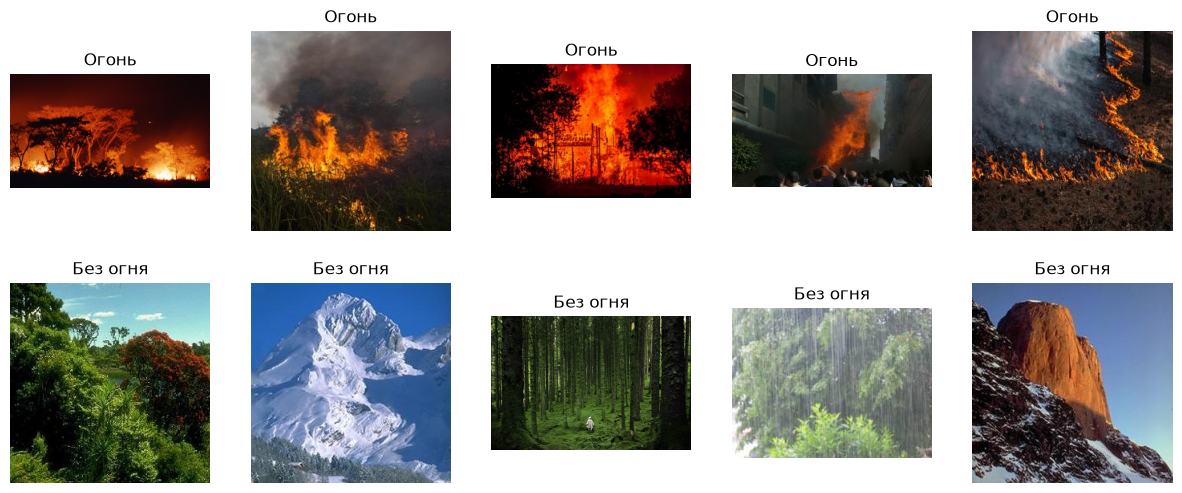

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fire_imgs = df[df['label'] == 1]['filepath'].sample(5).values
no_fire_imgs = df[df['label'] == 0]['filepath'].sample(5).values

for i, img_path in enumerate(fire_imgs):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[0, i].imshow(img)
    axes[0, i].set_title('Огонь')
    axes[0, i].axis('off')

for i, img_path in enumerate(no_fire_imgs):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[1, i].imshow(img)
    axes[1, i].set_title('Без огня')
    axes[1, i].axis('off')
plt.show()

## Разведывательный анализ данных, экстракция признаков из изображения и их визуализация

Итак, у нас есть датасет с 2947 изображениями на которых или есть огонь или его нет.  
Но никаких признаков кроме лейбла в них нет и также, нет понимания по каким признакам модель должна будет понять есть огонь на фотографии или нет.  
Предлагаю начать от обратного, сначала получим несколько признаков, которые сможем извлечь (не важно какими информативными они будут), обучим базовую модель (baseline), оценим важность признаков для модели (или моделей), их корреляцию, проведем статистические тесты. Далее примем решение об удалении старых или добавлении новых признаков

Так как огонь в большинстве случаев имеет красный или оранжевый или желтый цвет, предположим, что это будет важным признаком для модели, выделим их, а заодно признак "теплоты цвета". Также, сомневаюсь, что кто-то, когда-то, видел огонь, который не излучал бы свет, поэтому, предположим, что огонь яркий, а значит, для определения наличия огня будет признак яркости пикселя тоже важным признаком.  
Плюс ко всему, огонь никогда не имеет четкой ровной формы, она всегда рваная (неровная), поэтому признак формы тоже должен быть важен.  
Градиент соседних пикселей такжее важен, так как огонь сильно выделяется по цвету и яркости на фоне других негорящих предметов, а значит это тоже важный признак дял модели.

In [5]:
def color_features(path, size = (224,224)):
    """
    Функция для экстракции признаков пикселе из входных изображений
    
    Args: path - путь к файлу
          size - размер изображения

    Returns:
        признаки для создания изображения
    """

    img = cv2.imread(path)
    img = cv2.resize(img, (224, 224))
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)
    total = h.shape[0] * h.shape[1]

    red1 = cv2.inRange(hsv, (0, 70, 50), (10, 255, 255))
    red2 = cv2.inRange(hsv, (170, 70, 50), (180, 255, 255))
    red = cv2.bitwise_or(red1, red2)

    orange = cv2.inRange(hsv, (10, 70, 50), (25, 255, 255))
    yellow = cv2.inRange(hsv, (25, 70, 50), (35, 255, 255))
    warm = cv2.bitwise_or(red, cv2.bitwise_or(orange, yellow))

    red_ratio = np.count_nonzero(red) / total
    orange_ratio = np.count_nonzero(orange) / total
    yellow_ratio = np.count_nonzero(yellow) / total
    warm_ratio = np.count_nonzero(warm) / total

    bright_warm = np.count_nonzero(warm & (s > 120) & (v > 150)) / max(np.count_nonzero(warm), 1)
    s_warm = s[warm > 0]
    mean_s_warm = s_warm.mean() / 255 if s_warm.size else 0

    glcm = graycomatrix(gray, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
    glcm_contrast = graycoprops(glcm, 'contrast')[0, 0]
    glcm_homog = graycoprops(glcm, 'homogeneity')[0, 0]
    glcm_energy = graycoprops(glcm, 'energy')[0, 0]
    glcm_corr = graycoprops(glcm, 'correlation')[0, 0]

    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    hist, _ = np.histogram(lbp, bins=10, density=True)
    lbp_entropy = entropy(hist + 1e-9)

    edges = cv2.Canny(gray, 100, 200)
    edge_density = np.count_nonzero(edges) / total

    sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    grad_mag = np.sqrt(sx**2 + sy**2)

    # Форма тёплой маски
    num, labels, stats, centroids = cv2.connectedComponentsWithStats(warm, connectivity=8)
    if num > 1:
        areas = stats[1:, cv2.CC_STAT_AREA]
        idx = np.argmax(areas) + 1
        largest_area = areas[idx - 1] / total
        x, y, w, h = stats[idx, cv2.CC_STAT_LEFT], stats[idx, cv2.CC_STAT_TOP], \
                     stats[idx, cv2.CC_STAT_WIDTH], stats[idx, cv2.CC_STAT_HEIGHT]
        aspect = w / h if h else 0
        cx, cy = centroids[idx][0] / size[1], centroids[idx][1] / size[0]

        cnts, _ = cv2.findContours(warm, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        c = max(cnts, key=cv2.contourArea)
        area = cv2.contourArea(c)
        per = cv2.arcLength(c, True)
        compactness = 4 * np.pi * area / per**2 if per else 0
        hull = cv2.convexHull(c)
        hull_area = cv2.contourArea(hull)
        solidity = area / hull_area if hull_area else 0
    else:
        largest_area, aspect, cx, cy, compactness, solidity = 0, 0, 0, 0, 0, 0

    # FFT
    f = np.fft.fftshift(np.fft.fft2(gray))
    mag = np.abs(f)
    h_, w_ = mag.shape
    cy_, cx_ = h_ // 2, w_ // 2
    r_ = 20
    low = mag[cy_-r_:cy_+r_, cx_-r_:cx_+r_].sum() / mag.sum()
    high = 1 - low  

    return {
        'mean_R': r.mean(), 'mean_G': g.mean(), 'mean_B': b.mean(),
        'std_R': r.std(), 'std_G': g.std(), 'std_B': b.std(),
        'mean_H': h.mean(), 'mean_S': s.mean(),
        'red_ratio': red_ratio, 'orange_ratio': orange_ratio,
        'yellow_ratio': yellow_ratio, 'warm_ratio': warm_ratio,
        'bright_warm_ratio': bright_warm, 'mean_s_warm': mean_s_warm,
        'mean_brightness': v.mean(), 'std_brightness': v.std(),
        'contrast': gray.std(), 'p95_brightness': np.percentile(v, 95) / 255,
        'dark_ratio': np.mean(v < 40), 'bright_ratio': np.mean(v > 200),
        'glcm_contrast': glcm_contrast, 'glcm_homogeneity': glcm_homog,
        'glcm_energy': glcm_energy, 'glcm_correlation': glcm_corr,
        'lbp_entropy': lbp_entropy, 'edge_density': edge_density,
        'gradient_mean': grad_mag.mean(), 'gradient_std': grad_mag.std(),
        'image_entropy': entropy(cv2.calcHist([gray], [0], None, [256], [0, 256]) + 1e-9),
        'largest_component_ratio': largest_area, 'num_components': max(num - 1, 0),
        'solidity': solidity,
        'aspect_ratio': aspect, 'compactness': compactness,
        'centroid_y': cy, 'centroid_x': cx,
        'fft_low_energy': low, 'fft_high_energy': high,
    }


features = df['filepath'].apply(color_features).apply(pd.Series)
df = pd.concat([df, features], axis=1)


mean_R, mean_G, mean_B - средняя интенисвность каждого канала RGB  
std_R, std_G, std_B - стандартное отклонение по каждому из каналов RGB  
Это базовое описание цветовой палитры изображения  

Далее рассмотрим палитру HSV а именно:  
mean_H - (средний оттенок Hue)  
mean_S - средняя насыщенность (Saturation)  
mean_brightness - (средняя яркость)  
std_brightness - разброс яркости  
p95_brightness - 95-й перцентиль яркости / 255 — насколько ярки самые светлые участки  
dark_ratio - доля пикселей с V < 40 (тёмные области)  
bright_ratio - доля пикселей с V > 200 (светлые/пересвеченные области)  

Через построение бинарных масок теплых цветов (красного, желтого и оранжевого) с помощью cv2.inRange можем получить следующие признаки:  
red_ratio, orange_ratio, yellow_ratio доля пикселей каждого из цветов от всего кадра  
warm_ratio доля пикселей с "теплыми" цветами от всего кадра  
bright_warm_ratio - какая доля тёплых пикселей ещё и яркая  
mean_s_warm - средняя насыщенность только среди тёплых пикселей  

Рассмотрим форму тёплой маски (геометрия)  
С помощью connectedComponentsWithStats и findContours получим следующие признаки:  

largest_component_ratio - площадь самой крупной тёплой области / площадь кадра  
num_components - количество связных тёплых областей  
aspect_ratio - ширина / высота ограничивающего прямоугольника (w/h)  
compactness - показатель "ровности" фигуры 1 у круга меньше у "рваной" фигуры  
solidity	площадь контура / площадь его выпуклой оболочки — насколько форма «выпуклая»  
centroid_x, centroid_y	нормированные координаты центроида самой крупной области (0…1) — где она расположена в кадре  

Текстурные признаки (GLCM)    
glcm_contrast - локальный контраст (высокий — резкие перепады яркости)  
glcm_homogeneity - однородность (высокая — гладкие области)  
glcm_energy - упорядоченность (высокая — повторяющийся паттерн)  
glcm_correlation - линейная зависимость соседних пикселей  

LBP (локальные бинарные паттерны)  
Из гистограммы lbp (local binary patterns) получим lbp_entropy — энтропию этой гистограммы. Высокая = сложная/неоднородная микротекстура, низкая = однородная поверхность.

Края и градиенты  
edge_density - доля пикселей-краёв от Canny  
gradient_mean - средняя длина вектора градиента   
gradient_std - разброс величины градиента   

Энтропия изображения  
image_entropy — энтропия Шеннона по гистограмме яркости на 256 бинов. Мера информативности/«богатства» яркостной картины  

Частотные признаки (FFT)  
f — центрированное 2D-преобразование Фурье от серого изображения  
low = доля энергии в центральном окне 40×40 пикселей / вся энергия  
fft_high_energy = 1 − low  

Посмотрим на распределения признаков теплоты, красного цвета и яркости теплых оттенков для каждой из категории (лейблов)

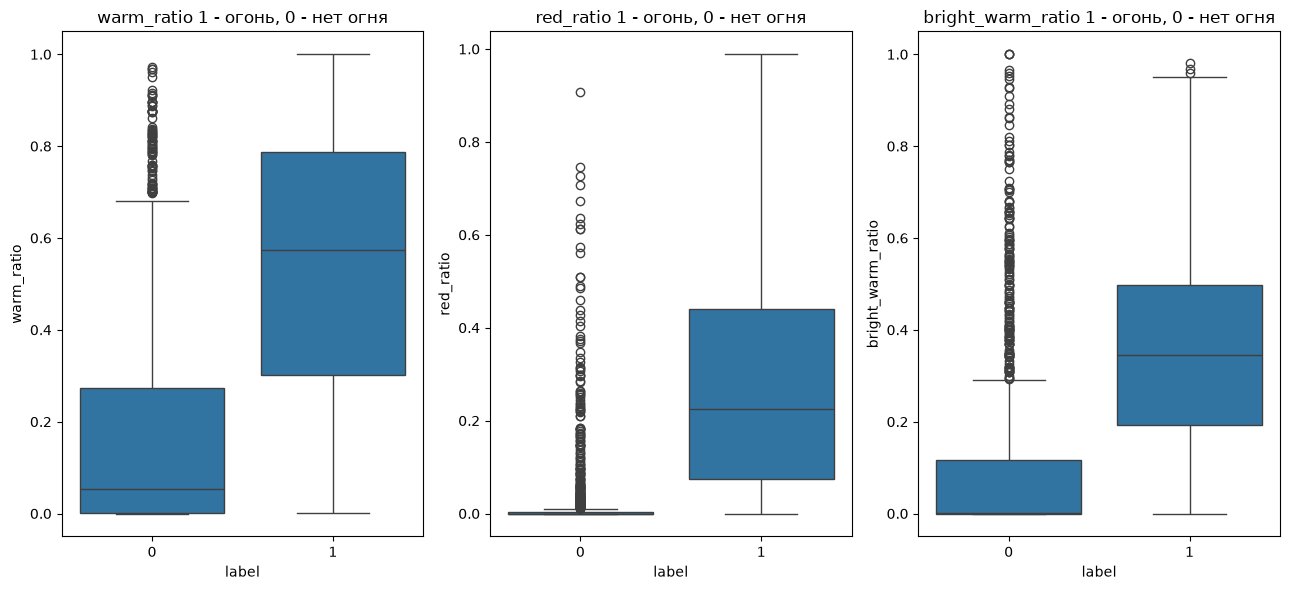

In [7]:
features_to_plot = ['warm_ratio', 'red_ratio', 'bright_warm_ratio']

fig, axes = plt.subplots(1, 3, figsize=(13,6))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    sns.boxplot(x='label', y=col, data=df, ax=axes[i])
    axes[i].set_title(f'{col} 1 - огонь, 0 - нет огня')

plt.tight_layout()
plt.show()

На первый взгляд разница большая, а значит, можно предположить что, для модели будут являться важными признаками.  
Проверим один из признаков с помощью статистических тестов.

Перед принятием решения о типе статистического теста, нам нужно понять являются ли распределения "нормальными", для этого проведем тест Шапиро-Уилка (так как в выборках меньше 5000 объектов)  

Гипотеза о нормальности распределений  
H₀: warm_ratio в классах label=1 и label=2 распределены по нормальному закону.  
H₁: Значения не распределены по нормальному закону.  

Гипотеза о различии распределений (базовая)  
H₀: распределения warm_ratio в классах label=1 и label=2 одинаковы.  
H₁: распределения различаются.  

In [8]:
g1 = df[df['label'] == 0]['warm_ratio']
g2 = df[df['label'] == 1]['warm_ratio']

# Тест Шапиро-Уилка
stat, p_value = stats.shapiro(df['warm_ratio'])

print(f"Статистика W = {stat:.4f}")
print(f"P-значение = {p_value:.4e}")

alpha = 0.05
if p_value > alpha:
    print("Не отвергаем H0: данные, вероятно, нормально распределены")
else:
    print("Отвергаем H0: данные, вероятно, НЕ нормально распределены")


Статистика W = 0.9013
P-значение = 4.9995e-40
Отвергаем H0: данные, вероятно, НЕ нормально распределены


Данные распределены не по нормальному закону, а значит, выбираем непараметрический тест Манна-Уитни

In [9]:
# Mann-Whitney U
u_stat, u_p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
print(f"Mann-Whitney U: U={u_stat:.4g}, p={u_p:.4g}")

if u_p < 0.05:
    print("Различие статистически значимо (p < 0.05) отвергаем нулевую гипотезу")
else:
    print("Различие статистически НЕ значимо (p ≥ 0.05) отвергаем нулевую гипотезу")

Mann-Whitney U: U=3.186e+05, p=4.865e-234
Различие статистически значимо (p < 0.05) отвергаем нулевую гипотезу


Распределения действительно различаются признаки должны быть инофрмативными

Давайте взглянем как это выглядит на картинке

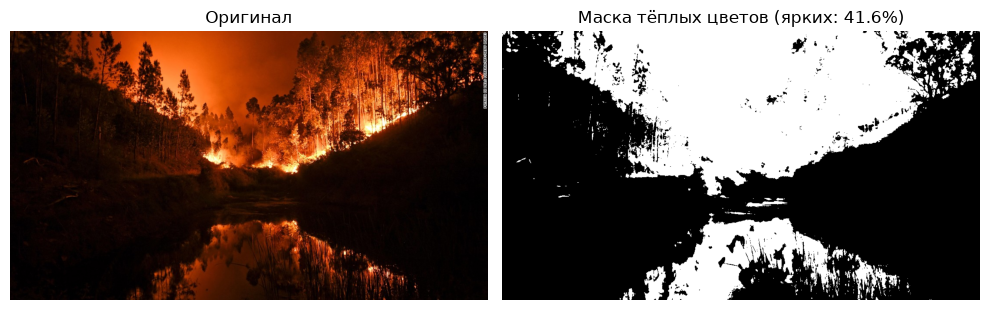

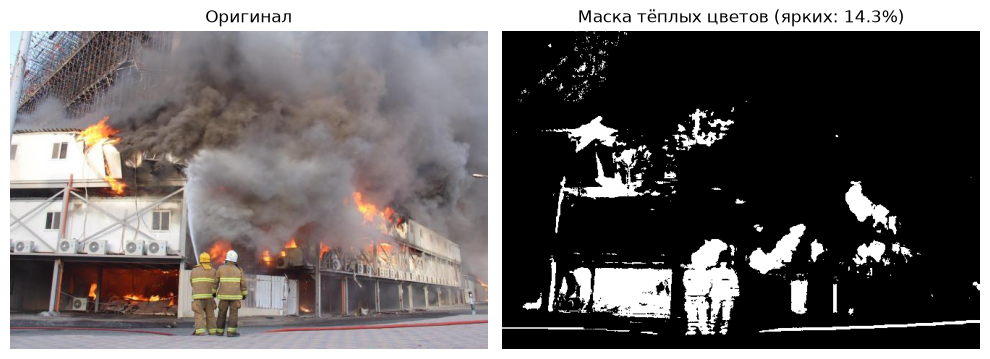

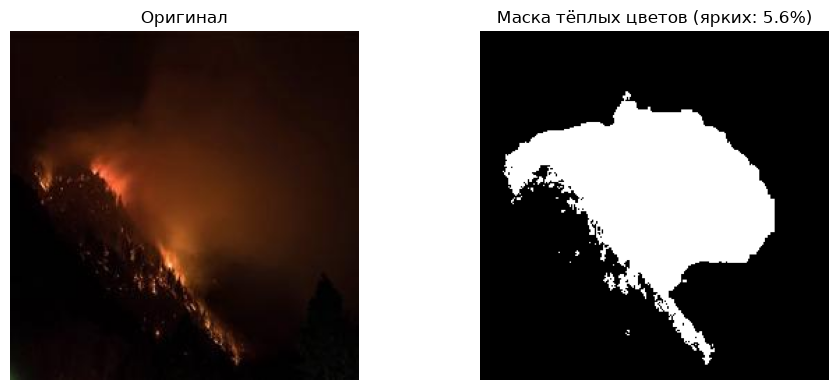

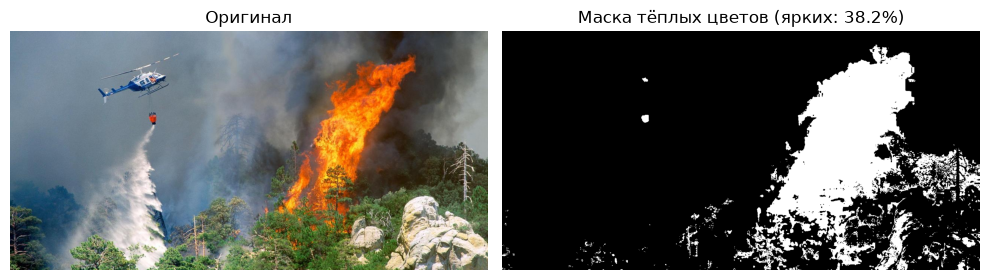

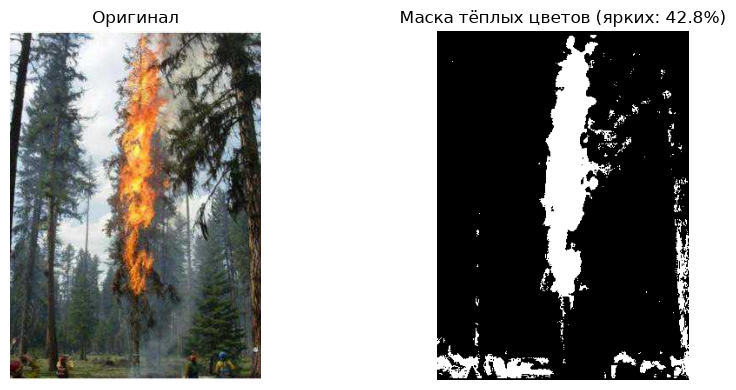

In [11]:
def show_warm_bright_mask(path, return_mask=False):
    """
        Строит и показывает маску «тёплых» цветов (красный/оранжевый/жёлтый),
        характерных для открытого пламени.
    """
    img = cv2.imread(path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    s, v = hsv[:, :, 1], hsv[:, :, 2]     # h не нужна

    red = cv2.bitwise_or(
        cv2.inRange(hsv, (0, 70, 50), (10, 255, 255)),
        cv2.inRange(hsv, (170, 70, 50), (180, 255, 255)),
    )
    orange = cv2.inRange(hsv, (10, 70, 50), (25, 255, 255))
    yellow = cv2.inRange(hsv, (25, 70, 50), (35, 255, 255))

    warm = cv2.bitwise_or(red, cv2.bitwise_or(orange, yellow))

    # маска ярких тёплых пикселей (bool), без count_nonzero и деления
    bright_warm = (warm > 0) & (s > 120) & (v > 150)

    # метрика: доля ярких тёплых среди всех тёплых
    warm_total = np.count_nonzero(warm)
    ratio = np.count_nonzero(bright_warm) / warm_total if warm_total else 0.0

    mask = warm
    

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(img_rgb); ax[0].set_title("Оригинал"); ax[0].axis("off")
    ax[1].imshow(mask, cmap="gray"); ax[1].set_title(
        f"Маска тёплых цветов (ярких: {ratio:.1%})"
    ); ax[1].axis("off")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

    if return_mask:
        return mask
    return None


# Воспроизводимая выборка трёх огней
for path in df[df["label"] == 1]["filepath"].sample(5):
    show_warm_bright_mask(path)

Как видно не всегда яркость и "теплота" цвета указывает именно на огонь, ведь не только огонь может иметь яркие теплые цвета на фотографии  
Например, как на картинках ниже:  

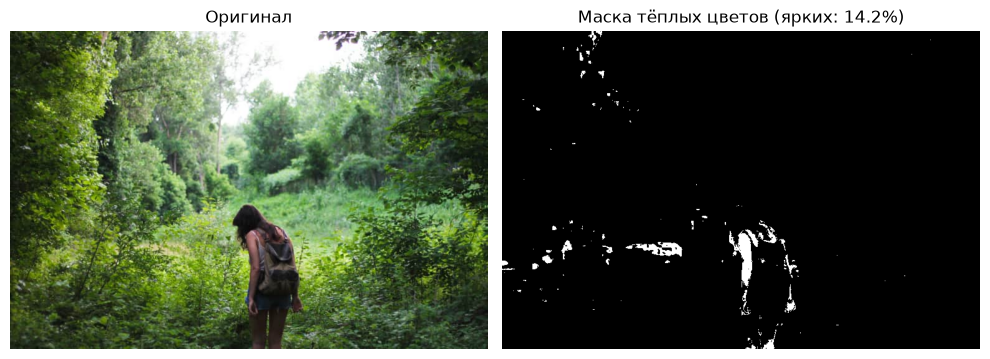

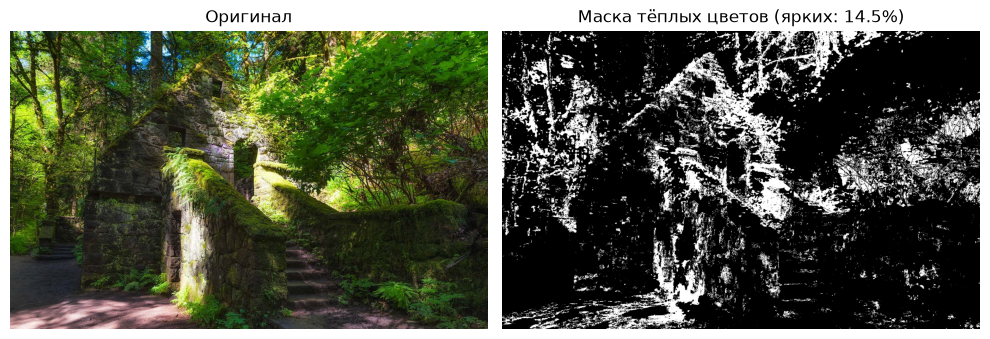

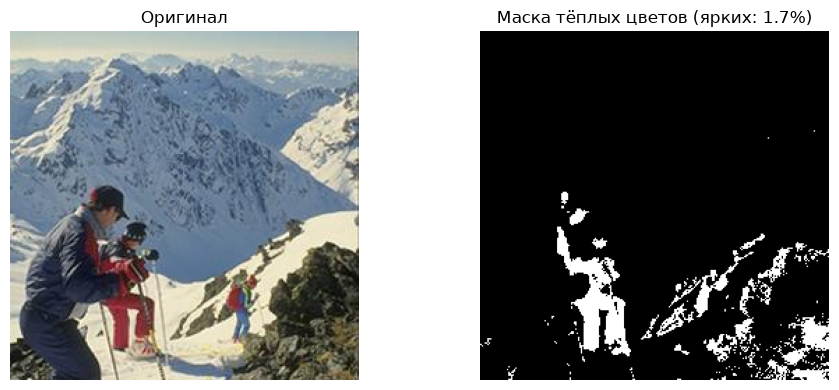

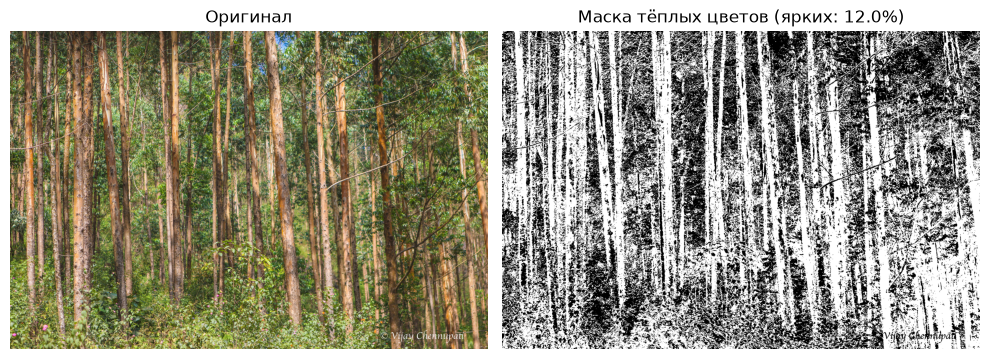

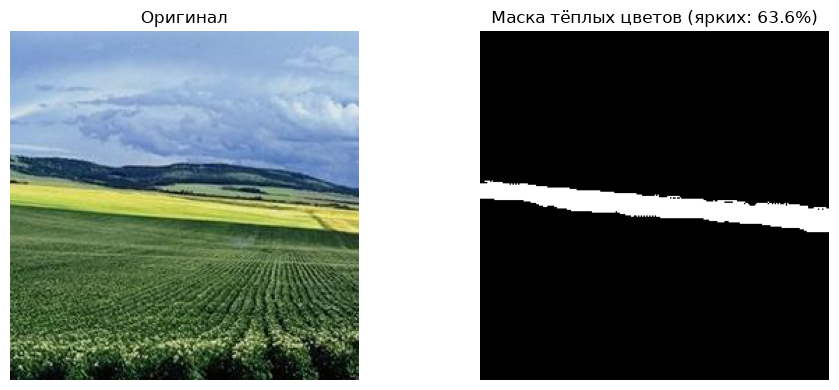

In [12]:
for path in df[df["label"] == 0]["filepath"].sample(5):
    show_warm_bright_mask(path)

Поэтому добавление текстурных и других признаков не было ошибкой 

## Обучение бейслайна

Попробуем обучить базовую модель в лице Логистической регресии с целью понять насколько модель может по имеющимся уже признакам хорошо классифицировать изображения на предмет наличия огня

In [13]:
# Разделяем на трэйн, тест и валидационные выборки
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=42)
train_df, val_df = train_test_split(train_df, test_size=0.2, stratify=train_df['label'], random_state=42)

In [14]:
print(train_df.shape)
print(test_df.shape)
print(val_df.shape)

(1885, 40)
(590, 40)
(472, 40)


In [15]:
# очистка от признаков содержащих пути к файлам и метки
X_train = train_df.drop(['label','filepath'], axis=1)
y_train = train_df['label']
X_test = test_df.drop(['label','filepath'], axis=1)
y_test = test_df['label']
val = val_df.drop(['label','filepath'], axis=1)

Для отслеживания результата нам нужно определить метрики по которым будет оцениваться результат работы модели.  
В контексте нашей задачи нужно ответить на два вопроса:  
1. какой процент пожаров я обнаружил из всех реальных пожаров?  
2. какой процент ложных тревог я допустил?  

На первый вопрос поможет ответить метрика Recall  
На второй вопрос метрика Precision  

Почему так? Если оценивать только Recall, то мы можем сделать "Модель-паникёр". Которая будет иметь огромную метрику Recall за счёт того, что она будет говорить, что огонь найден даже там, где его на самом деле нет. От таких случаев может спасти метрика Precision, которая будет отличать реальные срабатывания от ложных.

In [16]:
def baseline(X_train, y_train):
    """
    Функция  для стандартизации данных с помощью StandardScaler отбора наиболее значимых признаков и обучения LogisticRegresiion с подбором параметров с помощью GridSearchCV
    Возвращает DataFrame с названием признака и Коэффициентами важности их для модели отсортированные по абсолютному значению
    """
    # Определяем пайплайн 
    base_pipe = Pipeline([
                            ('scaler' , StandardScaler()),
                            ('selecter' , SelectKBest(f_classif)),
                            ('model' , LogisticRegression())
                            ])
    # Параметры для GridSearchCV
    param_grid = {
            'model__C': [0.01, 0.1, 1, 10, 15, 20],
            'selecter__k': [10, 25, 40, 42],
            'model__class_weight': ['balanced', None],
            'model__penalty': ['l1', 'l2']
        } 

    
    grid_search_base = GridSearchCV(base_pipe, param_grid, cv=5, scoring='recall')
    grid_search_base.fit(X_train, y_train)

    print(f"Лучшие параметры: {grid_search_base.best_params_}")
    print(f"Лучшая точность на кросс-валидации: {grid_search_base.best_score_:.4f}")        

    best_pipeline = grid_search_base.best_estimator_

     # Достаем шаги из лучшего пайплайна по их именам
    best_selector = best_pipeline.named_steps['selecter']
    best_model = best_pipeline.named_steps['model']

    #  Получаем маску отобранных признаков (True для тех, что прошли SelectKBest)
    selected_mask = best_selector.get_support()

    #  Получаем названия этих признаков из вашего DataFrame         
    selected_features = X_train.columns[selected_mask]

    #  Получаем коэффициенты лучшей логистической регрессии
    coefficients = best_model.coef_[0]

    coeff_df = pd.DataFrame({
       'Feature': selected_features,
        'Coefficient': coefficients
    })

    res = coeff_df.sort_values(by='Coefficient', ascending=False, key=abs)
    
    return res, best_pipeline

In [18]:
# Вызов функции
base_data = baseline(X_train, y_train)
best_base_model = base_data[1]

Лучшие параметры: {'model__C': 10, 'model__class_weight': None, 'model__penalty': 'l2', 'selecter__k': 40}
Лучшая точность на кросс-валидации: 0.9542


## Анализ бейслайна и признаков данных

In [19]:
# Вывод метрик
y_pred_log = base_data[1].predict(X_test)
rep_base = classification_report(y_pred_log, y_test,output_dict=True)
print(rep_base)

{'0': {'precision': 0.9019607843137255, 'recall': 0.9349593495934959, 'f1-score': 0.9181636726546906, 'support': 246.0}, '1': {'precision': 0.9522388059701492, 'recall': 0.9273255813953488, 'f1-score': 0.9396170839469808, 'support': 344.0}, 'accuracy': 0.9305084745762712, 'macro avg': {'precision': 0.9270997951419373, 'recall': 0.9311424654944224, 'f1-score': 0.9288903783008358, 'support': 590.0}, 'weighted avg': {'precision': 0.9312754274489962, 'recall': 0.9305084745762712, 'f1-score': 0.9306721022895175, 'support': 590.0}}


Взглянем на топ-10 важных признаков для логистической регрессии

In [20]:
base_data[0].head(10)

,Feature,Coefficient
26,gradient_mean,-8.052325
14,mean_brightness,-4.486985
0,mean_R,3.960469
2,mean_B,3.466562
21,glcm_homogeneity,-3.173852
27,gradient_std,3.097367
25,edge_density,2.576528
20,glcm_contrast,1.637095
8,red_ratio,1.495144
23,glcm_correlation,1.461541


Визуализируем для наглядности

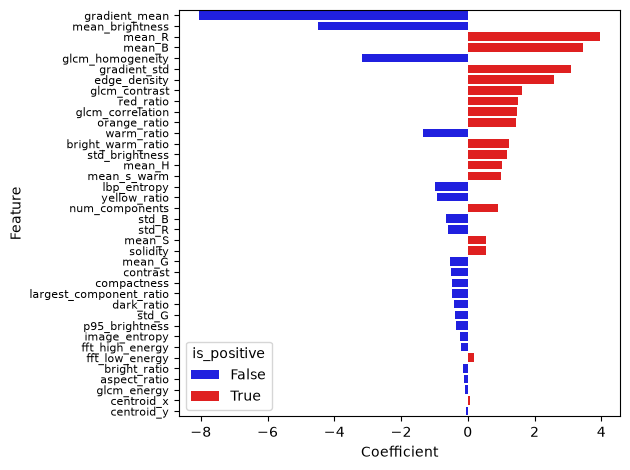

In [21]:
base_data[0]['is_positive'] = base_data[0]['Coefficient'].apply(lambda x: True if x > 0 else False)
plt.Figure(figsize=(10,15))
ax = sns.barplot(
    data=base_data[0],
    x='Coefficient',
    y='Feature',
    hue='is_positive',
    palette={True: 'red', False: 'blue'}
)
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()

Заметим, что метрики не идеальны, но мы уже можем по ним сделать выводы:  
Recall 0.96 4.6% пропусков, модель пропускает примерно каждый 22-й кадр на котором есть огонь  
Precision 0.925 7.5% ложных срабатываний означает: из 1000 тревог 75 ложных

В пространстве наших признаков наверняка можно увидеть сильно коррелировванные признаки.  
Проэксперементируем какие результаты будут если удалить их

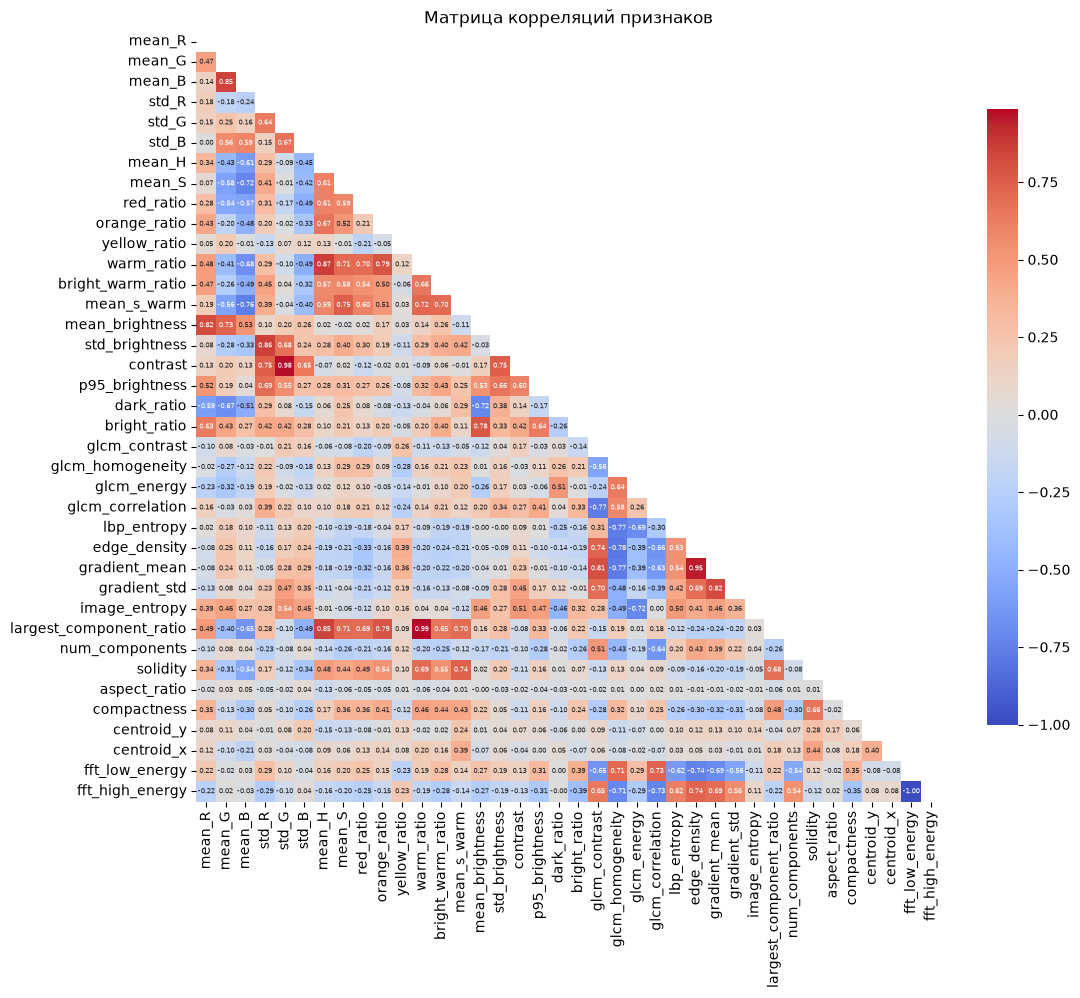

In [22]:
plt.figure(figsize=(12, 10))
# Берем только числовые признаки, без filepath
corr_matrix = df.select_dtypes(include=['float64', 'int64']).drop(columns=['label']).corr()

# Рисуем только нижний треугольник, чтобы не было дублей
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', center=0, annot=True, fmt='.2f', 
            annot_kws={"size": 5}, cbar_kws={"shrink": .8})
plt.title('Матрица корреляций признаков')
plt.show()

Да, и таких признаков не мало. Что если обучить модель нашего бейслайна на датасете без этих признаков?  
Будем считать сильной корреляцей значения выше 0.8

In [23]:
X2_train = X_train.drop(['mean_R','mean_G','std_R','std_G','mean_H','glcm_contrast','gradient_mean','fft_low_energy'], axis=1)
X2_test = X_test.drop(['mean_R','mean_G','std_R','std_G','mean_H','glcm_contrast','gradient_mean','fft_low_energy'], axis=1)

In [24]:
base2_data = baseline(X2_train, y_train)
best_base2_model = base2_data[1]

Лучшие параметры: {'model__C': 15, 'model__class_weight': None, 'model__penalty': 'l2', 'selecter__k': 40}
Лучшая точность на кросс-валидации: 0.9411


In [25]:
y_pred_log = base2_data[1].predict(X2_test)
rep_base2 = classification_report(y_pred_log, y_test, output_dict=True)
print(rep_base2)

{'0': {'precision': 0.9098039215686274, 'recall': 0.943089430894309, 'f1-score': 0.9261477045908184, 'support': 246.0}, '1': {'precision': 0.9582089552238806, 'recall': 0.9331395348837209, 'f1-score': 0.9455081001472754, 'support': 344.0}, 'accuracy': 0.9372881355932203, 'macro avg': {'precision': 0.9340064383962541, 'recall': 0.9381144828890149, 'f1-score': 0.9358279023690469, 'support': 590.0}, 'weighted avg': {'precision': 0.9380265174625376, 'recall': 0.9372881355932203, 'f1-score': 0.9374357996271255, 'support': 590.0}}


Однако, вторая модель оказалась совсем незначительно лучше первой, которая брала все признаки во внимание  
Надо полагать, что сильно скоррелированные признаки слабо влияют на метрику recall и логистическая регрессия справляется с этим с помощью l2 регуляризации

## Эксперименты с типами моделей и их комбинации

Попробуем обучить более сложную модель, например RandomForestClassfier  
Для нее, как раз не важно ни распределения признаков, ни их корреляция

In [26]:
def forest_classifier(X_train, y_train, X_test, y_test):
    """
    Функция для перебора параметров для RandomForestClassifier обучает модель с лучшими параметрами и возвращает таблицу с коеффициентами важности каждого признака
    """
    # Определяем модель
    rfc = RandomForestClassifier(n_jobs=-1, random_state=55, class_weight='balanced')
    # Сетка параметров 
    param_grid = {
        'n_estimators': [50,100,200,300,500,800,1000],
        'max_depth': [10,20,30,40,50],
        'min_samples_leaf': [5,10,20,25]
    }
    
    grid_search = GridSearchCV(rfc, param_grid=param_grid, cv=5, scoring='recall')
    grid_search.fit(X_train, y_train)
    
    print(f"Лучшие параметры: {grid_search.best_params_}")
    print(f"Лучшая точность на кросс-валидации: {grid_search.best_score_:.4f}")
    
    
    result = permutation_importance(
    grid_search.best_estimator_,      
    X_test, y_test,
    n_repeats=10,
    random_state=42,
    scoring="recall",       
    n_jobs=-1,
    )
    
    feature_names = X_train.columns

    perm = pd.DataFrame({
        "feature": feature_names,
        "importance_mean": result.importances_mean
    }).sort_values("importance_mean", ascending=False) 
        
    return perm, grid_search.best_estimator_

### Внимание! Не запускайте код если не готовы ждать, следующая ячейка выполняется дольше 15 минут

In [27]:
# Вызов функции
forest_data = forest_classifier(X_train, y_train, X_test, y_test)
best_forest_model = forest_data[1]

Лучшие параметры: {'max_depth': 20, 'min_samples_leaf': 5, 'n_estimators': 800}
Лучшая точность на кросс-валидации: 0.9654


In [28]:
# Вывод метрик
y_pred_forest = best_forest_model.predict(X_test)
rep_forest = classification_report(y_pred_forest, y_test,output_dict=True)
print(rep_forest)

{'0': {'precision': 0.9372549019607843, 'recall': 0.9446640316205533, 'f1-score': 0.9409448818897638, 'support': 253.0}, '1': {'precision': 0.9582089552238806, 'recall': 0.9525222551928784, 'f1-score': 0.9553571428571429, 'support': 337.0}, 'accuracy': 0.9491525423728814, 'macro avg': {'precision': 0.9477319285923325, 'recall': 0.9485931434067159, 'f1-score': 0.9481510123734533, 'support': 590.0}, 'weighted avg': {'precision': 0.9492235730619089, 'recall': 0.9491525423728814, 'f1-score': 0.9491769699338432, 'support': 590.0}}


Метрики незначительно выросли, но времени и ресурсов на обучение затрачено гораздно больше для случайного леса в сравнении с логистической регрессией

Попробуем обьединить наши две модели с целью повысить метрики с помощью Stacking метода

In [29]:
estimators = [
    ('lr', best_base_model),
    ('rf', best_forest_model)
]

stack = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(class_weight='balanced',random_state=55,max_iter=1000),
    cv=5,                      
    passthrough=False,         
    stack_method="predict_proba",
    n_jobs=-1
)

stack.fit(X_train,y_train)



,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('lr', ...), ('rf', ...)]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...ndom_state=55)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",5
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'predict_proba'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[Pipeline(step...nalty='l2'))]), RandomForestC...ndom_state=55)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](38,)"

In [30]:
y_pred = stack.predict(X_test)
print(recall_score(y_pred, y_test))
rep_stack = classification_report(y_pred, y_test,output_dict=True)
print(rep_stack)

0.9608433734939759
{'0': {'precision': 0.9490196078431372, 'recall': 0.937984496124031, 'f1-score': 0.9434697855750487, 'support': 258.0}, '1': {'precision': 0.9522388059701492, 'recall': 0.9608433734939759, 'f1-score': 0.9565217391304348, 'support': 332.0}, 'accuracy': 0.9508474576271186, 'macro avg': {'precision': 0.9506292069066432, 'recall': 0.9494139348090034, 'f1-score': 0.9499957623527417, 'support': 590.0}, 'weighted avg': {'precision': 0.9508310888230829, 'recall': 0.9508474576271186, 'f1-score': 0.9508142746943508, 'support': 590.0}}


И снова можем увидеть, что метрики не растут, попробуем добавить в стекинг LightGBM (градиентный бустинг), предполагая, что новый мета-признак лучшим образом окажет влияние на предсказания мета-модели

In [31]:
estimators = [
    ('lr', best_base_model),
    ('rf', best_forest_model),
    ('lgbm', LGBMClassifier())
]

stack = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(class_weight='balanced',random_state=55,max_iter=1000),
    cv=5,                      
    passthrough=False,         
    stack_method="predict_proba",
    n_jobs=-1
)

stack.fit(X_train,y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('lr', ...), ('rf', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...ndom_state=55)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",5
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'predict_proba'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[Pipeline(step...nalty='l2'))]), RandomForestC...ndom_state=55), LGBMClassifier()]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0"

In [32]:
y_pred = stack.predict(X_test)
rep_stack2 = classification_report(y_pred, y_test,output_dict=True)
print(rep_stack2)

{'0': {'precision': 0.9529411764705882, 'recall': 0.9529411764705882, 'f1-score': 0.9529411764705882, 'support': 255.0}, '1': {'precision': 0.9641791044776119, 'recall': 0.9641791044776119, 'f1-score': 0.9641791044776119, 'support': 335.0}, 'accuracy': 0.9593220338983051, 'macro avg': {'precision': 0.9585601404741, 'recall': 0.9585601404741, 'f1-score': 0.9585601404741, 'support': 590.0}, 'weighted avg': {'precision': 0.9593220338983051, 'recall': 0.9593220338983051, 'f1-score': 0.9593220338983051, 'support': 590.0}}


Не наблюдая кординальных улучшений метрик можно предположить, что проблема не в работе самих моделей, а в признаках которые мы выделили. Чтобы отработать эту теорию можно попробовать применить модель глубокого машинного обучения tf.keras.Sequental которая может самостоятельно выделить признаки по которым построит предсказание

## Обучение модели глубокого машинного обучения и сравнение метрик 

In [33]:
df2 = pd.DataFrame(data, columns=['filepath', 'label'])

In [34]:
# Разделяем на трэйн, тест и валидационные выборки
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=42)
train_df, val_df = train_test_split(train_df, test_size=0.2, stratify=train_df['label'], random_state=42)

In [35]:
# Преобразуем лейблы из чисел в строковые категории для подачи в модель
for l in [train_df, test_df, val_df]:
    l['label'] = l['label'].map({1:'Fire', 0:'NoFire'})

In [36]:
# Размер входного изображения
IMG_SIZE = (224, 224)      
# Размер батча. Влияет на скорость обучения и потребление памяти GPU                                                                     
BATCH_SIZE = 32

# Создание генераторов для аугментации и масштабирования
train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    brightness_range=[0.9, 1.1],
)

val_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_dataframe(
    train_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='binary', color_mode='rgb',
    shuffle=True, seed=55,
    zoom_range=(0.5, 1.5)
)

val_gen = val_datagen.flow_from_dataframe(
    val_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='binary', color_mode='rgb',
    shuffle=False,
    zoom_range=(0.5, 1.5)
)
test_gen = val_datagen.flow_from_dataframe(
    test_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='binary', color_mode='rgb',
    shuffle=False,
    zoom_range=(0.5, 1.5)
)

print("Классы:", train_gen.class_indices)
print("train:", np.bincount(train_gen.classes))
print("val:  ", np.bincount(val_gen.classes))
print("test: ", np.bincount(test_gen.classes))

Found 1885 validated image filenames belonging to 2 classes.
Found 472 validated image filenames belonging to 2 classes.
Found 590 validated image filenames belonging to 2 classes.
Классы: {'Fire': 0, 'NoFire': 1}
train: [1069  816]
val:   [268 204]
test:  [335 255]


In [37]:
# MobileNetV2 без верхних слоёв классификации
base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights='imagenet'
)
base.trainable = False
# Определение модели и параметров
model = Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(scale=2.0, offset=-1.0),   
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid'),
])

In [38]:
# компиляция классификатора огня с метриками recall/precision/PR-AUC
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.AUC(name='auc_pr', curve='PR'),
    ],
)

In [39]:
# добавлены колбэки для обучения классификатора огня и функцией ранней остановки
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_fire.keras", monitor='val_recall', mode='max',
        save_best_only=True, verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_recall', mode='max',
        patience=5, restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_recall', mode='max',
        factor=0.5, patience=3, min_lr=1e-6, verbose=1,
    ),
]

In [40]:
# расчёт class_weight для компенсации дисбаланса классов
cw = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_gen.classes),
    y=train_gen.classes,
)
class_weight = dict(enumerate(cw))
print(class_weight)

{0: np.float64(0.881665107577175), 1: np.float64(1.1550245098039216)}


### Внимание! Не запускайте код если не готовы ждать, следующая ячейка выполняется дольше 15 минут

In [41]:
# запуск обучения
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1,
)

Epoch 1/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9151 - auc_pr: 0.9660 - loss: 0.2123 - precision: 0.8905 - recall: 0.9167
Epoch 1: val_recall improved from None to 0.94118, saving model to best_fire.keras

Epoch 1: finished saving model to best_fire.keras
59/59 ━━━━━━━━━━━━━━━━━━━━ 154s 2s/step - accuracy: 0.9151 - auc_pr: 0.9660 - loss: 0.2123 - precision: 0.8905 - recall: 0.9167 - val_accuracy: 0.9703 - val_auc_pr: 0.9971 - val_loss: 0.0852 - val_precision: 0.9897 - val_recall: 0.9412 - learning_rate: 0.0010
Epoch 2/20
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9676 - auc_pr: 0.9924 - loss: 0.0985 - precision: 0.9587 - recall: 0.9669
Epoch 2: val_recall improved from 0.94118 to 0.97549, saving model to best_fire.keras

Epoch 2: finished saving model to best_fire.keras
59/59 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.9676 - auc_pr: 0.9924 - loss: 0.0985 - precision: 0.9587 - recall: 0.9669 - val_accuracy: 0.9809 - val_auc_pr: 0.9986 - val_loss: 0.0457 - va

In [ ]:
# Метрики предсказаний на val_df 
y_proba = model.predict(val_gen).ravel()
y_true  = val_gen.classes

# Кривая precision-recall
prec, rec, thr = precision_recall_curve(y_true, y_proba)
mask = rec >= 0.95

#  Подбор порога с максимальным precision
idx = np.where(mask)[0]                 
if len(idx) > 0:
    best_idx = idx[np.argmax(prec[idx])]  
    best_thr = float(thr[best_idx])
else:
    best_thr = 0.5
    
best_thr = thr[np.argmax(prec[mask])] if mask.any() else 0.5
print(f"PR-AUC: {auc(rec, prec):.4f}, порог: {best_thr:.3f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step
PR-AUC: 0.9986, порог: 0.689


In [43]:
# Метрики при выбранном пороге
y_pred = (y_proba >= best_thr).astype(int)
rep_neuro = classification_report(y_true, y_pred, output_dict=True)
print(rep_neuro)
print(confusion_matrix(y_true, y_pred))

{'0': {'precision': 0.9708029197080292, 'recall': 0.9925373134328358, 'f1-score': 0.981549815498155, 'support': 268.0}, '1': {'precision': 0.98989898989899, 'recall': 0.9607843137254902, 'f1-score': 0.9751243781094527, 'support': 204.0}, 'accuracy': 0.9788135593220338, 'macro avg': {'precision': 0.9803509548035096, 'recall': 0.976660813579163, 'f1-score': 0.9783370968038039, 'support': 472.0}, 'weighted avg': {'precision': 0.9790563059770038, 'recall': 0.9788135593220338, 'f1-score': 0.9787727196776143, 'support': 472.0}}
[[266   2]
 [  8 196]]


Метрики значительно лучше посравнению с разницами между другими моделями, но Recall для класса огня вырос не сильно.  


Сохранение файлов с обученной моделью и файла с метаданными для модели

In [54]:
class_names = ['fire', 'nofire']
img_size = (224, 224)
model_path = "fire_detector_TFKeras.keras"
meta_path = "fire_detector_meta.json"

model.save(model_path)

meta = {
    "model_path":   model_path,
    "threshold":    float(best_thr),
    "class_names":  class_names,
    "img_size":     list(img_size),
    "preprocessing": {
        "rescale":   "1./255",
        "mobilenet_range": "[-1, 1] (Rescaling scale=2.0, offset=-1.0 внутри модели)",
    }
}

with open(meta_path, "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

print(f"\nМодель:     {model_path}")
print(f"Метаданные: {meta_path}")


Модель:     fire_detector_TFKeras.keras
Метаданные: fire_detector_meta.json


In [58]:
def predict_image(path):
    
    """
    Принимает путь к файлу или ссылку на него в сети
    Возвращает метку (label) и вероятность
    """
    
    with open("fire_detector_meta.json", encoding="utf-8") as f:
        meta = json.load(f)
    model = tf.keras.models.load_model(meta['model_path'])
    
    
    try:
        img = tf.keras.utils.load_img(path, target_size=meta['img_size'], color_mode="rgb")
        x = tf.keras.utils.img_to_array(img) / 255.0   
        x = np.expand_dims(x, axis=0)
    
    except:
        all([urlparse(path).scheme in ("http", "https"), urlparse(path).netloc])
        img = tf.keras.utils.get_file(origin=path)
        img = tf.keras.utils.load_img(img, target_size=(224, 224))
        x = tf.keras.utils.img_to_array(img) / 255.0   
        x = np.expand_dims(x, axis=0)                
    
    
        
    proba = float(model.predict(x, verbose=0).ravel()[0])
    label = meta['class_names'][int(proba >= meta['threshold'])]
    
    return label, proba




label, proba = predict_image(input('Путь или ссылка к картинке которую нужно определить').replace('\\','/'))
print(f"{label}  (p(fire)={proba:.4f})")

fire  (p(fire)=0.1945)


## Подведение итогов


In [57]:
reports = {
    'base': rep_base,
    'base2': rep_base2,
    'forest': rep_forest,
    'stack': rep_stack,
    'stack2': rep_stack2,
    'neuro': rep_neuro
    }

result = pd.DataFrame(
    {
        "recall_fire":    {name: r["1"]["recall"]    for name, r in reports.items()},
        "precision_fire": {name: r["1"]["precision"] for name, r in reports.items()},
        "recall_nofire":    {name: r["0"]["recall"]    for name, r in reports.items()},
        "precision_nofire": {name: r["0"]["precision"] for name, r in reports.items()},
    }
)

print(result)

        recall_fire  precision_fire  recall_nofire  precision_nofire
base       0.927326        0.952239       0.934959          0.901961
base2      0.933140        0.958209       0.943089          0.909804
forest     0.952522        0.958209       0.944664          0.937255
stack      0.960843        0.952239       0.937984          0.949020
stack2     0.964179        0.964179       0.952941          0.952941
neuro      0.960784        0.989899       0.992537          0.970803


Итак, мы обучили несколько типов моделей классического машинного обучения все они имеют неплохие метрики, но для реальных задач этого недостаточно.  
Для улучшения показателей я склонен считать, что количества собранных данных оказалось недостаточно, решая реальную задачу нужно собрать больше данных и расширить их разнообразие.  

Но мы видим, что модель глубокого машинного обучения справилась лучше даже на этих данных, сняв с нас задачу выделять признаки самостоятельно, существенно сократив время работы, да и ее результаты можно было бы улучшить подав в модель больше данных.   
  
Исходя из этого, я считаю, что для выполнения подобных задач (Классификации изображений), оссобенно в таких сферах как Пожарная безопасность, Медицина, и подобные сферы,использование моделей глубокого машинного обучения (Нейросетей) целесообразно, даже если это затратит много ресурсов.    